# Meu Ciclo+ | Classificação supervisionada
**Responsável: Lucca.** Estudo retrospectivo do aumento anual de notificações agregadas. Não é predição de risco individual. Consulte `MODELAGEM.md`. O teste de 2024 fica reservado; seleção por CV temporal anterior.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
candidatos = [Path('modelo'), Path('../modelo'), Path('data-science/modelo')]
pasta = next((p.resolve() for p in candidatos if (p/'ml_sinan.py').is_file()), None)
if pasta is None:
    raise FileNotFoundError('Execute a partir de data-science ou notebooks.')
sys.path.insert(0, str(pasta))
import ml_sinan as ml
base = ml.carregar()
print('Base:', base.shape, 'Total:', base.frequencia.sum())

Base: (270, 3) Total: 2775742


## Atributos e alvo
Três atributos calculados só com os três anos anteriores ao alvo. O último ano sem alvo observado é excluído. Classe 0 = sem aumento; 1 = aumento.

In [2]:
dados = ml.atributos_classificacao(base)
display(dados.head())
display(pd.crosstab(dados.ano_alvo,dados.aumento))

,uf,ano,ano_alvo,ultimo_log_crescimento,media_log_crescimento_2a,desvio_log_crescimento_2a,aumento
0,Acre,2017,2018,0.247962,0.162138,0.085823,0
1,Acre,2018,2019,-0.124399,0.061781,0.186180,0
2,Acre,2019,2020,-0.075508,-0.099953,0.024446,0
3,Acre,2020,2021,-0.168137,-0.121822,0.046315,1
4,Acre,2021,2022,0.264847,0.048355,0.216492,0


aumento,0,1
ano_alvo,,
2018,1,26
2019,3,24
2020,25,2
2021,4,23
2022,1,26
2023,0,27
2024,8,19


## Treinamento e avaliação
Quatro dobras expansivas (2020 a 2023); teste final 2024. Comparamos três classificadores e duas referências. Seleção por F1 macro; o teste não decide hiperparâmetros.

In [3]:
r, pred = ml.executar_classificacao()
campos = ["acuracia", "precisao_macro", "recall_macro", "f1_macro", "balanceada"]
cv=pd.DataFrame(r["cv"]).T[campos]
teste=pd.DataFrame(r["teste_reservado"]).T[campos]
display(cv)
display(teste)
print("Modelo escolhido:",r["candidato"])
print("Critério exploratório atendido:",r["criterio_atendido"])

,acuracia,precisao_macro,recall_macro,f1_macro,balanceada
logistica,0.555556,0.523142,0.528205,0.512782,0.528205
arvore,0.527778,0.51548,0.519231,0.496296,0.519231
random_forest,0.611111,0.564935,0.576923,0.5625,0.576923
maioria,0.722222,0.361111,0.5,0.419355,0.5
persistencia,0.546296,0.452727,0.45,0.45098,0.45


,acuracia,precisao_macro,recall_macro,f1_macro,balanceada
random_forest,0.481481,0.423529,0.414474,0.416667,0.414474
maioria,0.703704,0.351852,0.5,0.413043,0.5
persistencia,0.703704,0.351852,0.5,0.413043,0.5


Modelo escolhido: random_forest
Critério exploratório atendido: False


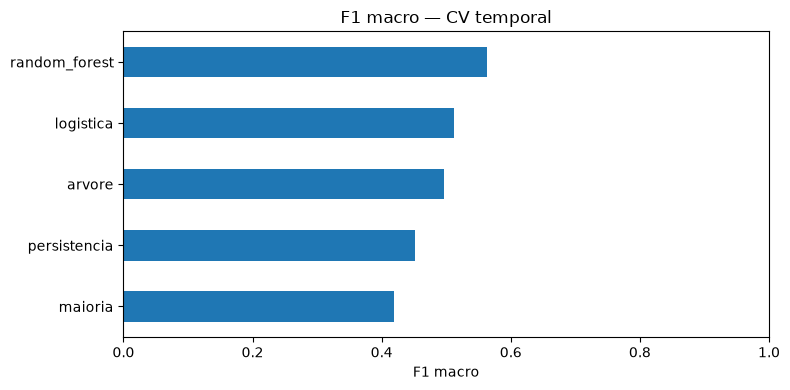

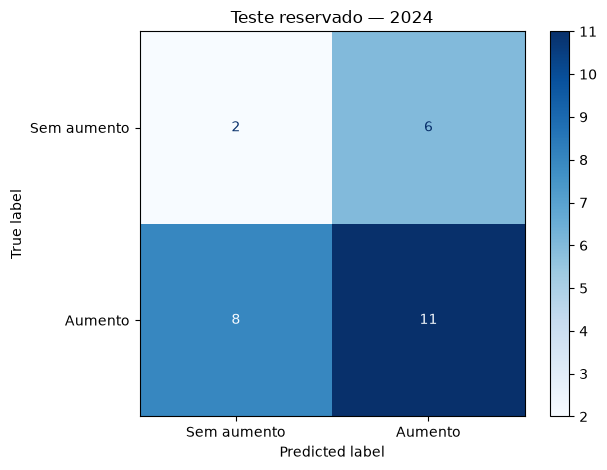

In [4]:
ax=cv.f1_macro.sort_values().plot.barh(figsize=(8,4),title="F1 macro — CV temporal")
ax.set_xlim(0,1); ax.set_xlabel("F1 macro"); plt.tight_layout(); plt.show()
from sklearn.metrics import ConfusionMatrixDisplay
import numpy as np
ConfusionMatrixDisplay(np.array(r["teste_reservado"][r["candidato"]]["matriz_confusao"]),display_labels=["Sem aumento","Aumento"]).plot(cmap="Blues")
plt.title("Teste reservado — 2024"); plt.tight_layout(); plt.show()

## Interpretação
O resultado é acadêmico e deve ser comparado com as referências. Não publicar previsão, mesmo se os critérios forem atingidos. As observações repetem UFs e a série inclui mudanças de notificação e pandemia. Os dados não medem risco nem incidência.